# 4. Validity checks, manuscript tables and figures

This notebook is step 4 of 5. It needs the results of notebooks 1–3.

| Section | What it does | Manuscript |
|---|---|---|
| 1 | Glucose distributions, test timing, selection, paired classification | Tables SA3, SA4, SA9, SA11, SA12 |
| 2 | Formatted tables and the main figures | Tables 1–2, Figs 1–2, Figs SA1 and SA3 |
| 3 | Scale-independent checks: log-FPG model, threshold sweep and others | Results 3.4, Table SA15, Fig. SA2 |

## Setup

In [1]:
# Find the project folder, wherever the notebook was opened from
root <- normalizePath(getwd(), winslash = "/")
while (!file.exists(file.path(root, "gdm-project.Rproj"))) {
  if (dirname(root) == root) stop("Open this notebook inside the gdm-project folder.")
  root <- dirname(root)
}
setwd(root)

# Use the package versions locked in renv.lock
if (!nzchar(Sys.getenv("RENV_PROJECT"))) {
  Sys.setenv(RENV_CONFIG_NAMESPACES_CHECK = "FALSE")
  source("renv/activate.R")
}
options(width = 120)

# Settings (config/config.yml) and analysis functions (src/)
source(here::here("src", "common", "setup.R"))

# Data saved by notebook 1
women  <- readRDS(data_file("women"))
sample <- readRDS(data_file("analytic_sample"))

## 1. Validity checks

Functions: `src/common/validity_checks.R`.

### Glucose distribution

Pregnant and non-pregnant women on both scales. Non-pregnant women give a comparison for the level of glucose.

In [2]:
fpg <- rbind(fpg_distribution(women, "fpg"), fpg_distribution(women, "fpg_alt"))
print(fpg)
save_table(fpg, "fpg_distribution")

    scale                        group    n      q25   median      q75 pct_fpg_5.1_or_more    se_5.1
1     fpg                     Pregnant  276 4.800000 5.400000 5.900000            64.97025 3.3038234
2     fpg                 Non-pregnant 4736 5.500000 6.000000 6.500000            90.18902 0.6357387
3     fpg Non-pregnant, same age range 3662 5.500000 6.000000 6.500000            89.13687 0.7491948
4 fpg_alt                     Pregnant  276 4.333333 4.833333 5.333333            33.74514 3.1657025
5 fpg_alt                 Non-pregnant 4736 4.944444 5.444444 5.888889            69.70256 1.1775894
6 fpg_alt Non-pregnant, same age range 3662 4.944444 5.388889 5.833333            67.78063 1.2997069
  pct_fpg_7.0_or_more    se_7.0
1            2.105179 0.9369868
2           14.230423 0.6564290
3           11.939547 0.7132392
4            0.888840 0.6348252
5            6.317770 0.4202824
6            4.637811 0.4251762


### Digit preference, timing and selection

- **Heaping:** digit preference in recorded glucose.
- **Prevalence by month:** GDM by completed month of pregnancy.
- **Timing by socioeconomic position:** whether some groups were tested earlier.
- **Selection:** included against excluded women at each selection step.

In [3]:
save_table(glucose_heaping(women), "glucose_heaping")
save_table(do.call(rbind, lapply(names(scales), function(s) {
  cbind(scale = s, prevalence_by_month(sample, women, scales[[s]]))
})), "prevalence_by_month")

timing <- timing_by_ses(sample, women)
print(timing)
save_table(timing, "timing_by_ses")
save_table(selection_comparison(women, cfg), "selection_comparison")

   variable   level   n    first   second    third mean_completed_months    p_value
1 residence   Rural 187 26.17299 37.53337 36.29364              5.379512 0.03729651
2 residence   Urban  77 42.01736 35.65394 22.32870              4.625658 0.03729651
3    wealth  Lowest  88 27.73728 46.98011 25.28261              4.991565 0.11885609
4    wealth  Middle  90 26.13420 35.37887 38.48693              5.384863 0.11885609
5    wealth Highest  86 36.20469 27.90119 35.89412              5.257771 0.11885609


### The same women on both scales

The paired classification shows how each woman is classified on the two scales, and the common sample repeats the main models on the same women.

In [4]:
paired <- paired_classification(sample, women, cfg)
print(paired)
save_table(paired, "paired_classification")

common <- common_sample(sample, women, cfg)
print(common)
save_table(common, "common_sample")

        released    unconverted  n        pct   ci_lower  ci_upper
1         Normal         Normal 97 35.9700507 29.6440881 42.824272
2      GDM range         Normal 79 31.1324857 25.1174241 37.859734
3      GDM range      GDM range 88 30.7357754 24.9689921 37.174553
4 Diabetes range      GDM range  3  1.2489890  0.4025665  3.807044
5 Diabetes range Diabetes range  3  0.9126991  0.2219797  3.673554
                           sample       scale   n events prevalence prevalence_ci_lower prevalence_ci_upper
1 Below 7.0 mmol/L on both scales    released 264    167  0.6323521           0.5629805           0.6966454
2 Below 7.0 mmol/L on both scales    released 264    167  0.6323521           0.5629805           0.6966454
3 Below 7.0 mmol/L on both scales unconverted 264     88  0.3141487           0.2553640           0.3795677
4 Below 7.0 mmol/L on both scales unconverted 264     88  0.3141487           0.2553640           0.3795677
5   Diabetes range counted as GDM    released 270    173  

## 2. Manuscript tables and figures

These cells format the saved results. Functions: `src/bdhs2022/tables_figures.R`.

In [5]:
effects <- read_table("effects_main")
pr <- effects[effects$measure == "PR", ]
ci <- read_table("inequality_bootstrap")

# Formatted tables, as they appear in the manuscript and supplement
save_table(table1_wealth(read_table("table1_by_wealth"), read_table("table1_categorical"), read_table("table1_continuous")),
           "manuscript_table1")
save_table(effects_table(pr, with_p = FALSE), "manuscript_table2")
save_table(effects_table(effects[effects$measure == "OR", ]), "manuscript_table_or")
save_table(inequality_table(ci, read_table("decomposition_main")), "manuscript_table3")
save_table(inequality_table(ci, read_table("decomposition_main"), full = TRUE), "manuscript_table_decomp_full")
save_table(inequality_table(ci, read_table("decomposition_with_wealth"), full = TRUE),
           "manuscript_table_decomp_wealth")
save_table(sensitivity_table(read_table("sensitivity_prevalence"), read_table("sensitivity_effects"),
                             read_table("sensitivity_inequality")), "manuscript_table_sensitivity")
save_table(effects_table(read_table("effects_anchor")), "manuscript_table_anchor")
save_table(effects_table(read_table("effects_hypertension")), "manuscript_table_hypertension")

### Figures

Each figure is written twice: a vector PDF with embedded fonts and a 1000-dpi PNG, the formats the journal accepts. This is the slowest step in this notebook.

In [6]:
# Path of a figure file (the PDF is written beside it)
fig <- function(name) file.path(dir_figures, paste0(name, ".png"))

**Fig. 1.** Selection of the study sample. [Open the file](../output/bdhs2022/figures/Figure_1.png)

In [7]:
plot_flow(read_table("sample_flow"), fig("Figure_1"), n_alt = sum(!is.na(sample$gdm_alt)))

**Fig. 2.** Wealth-related inequality: (A) concentration curves, (B) contributions to the Erreygers index. [Open the file](../output/bdhs2022/figures/Figure_2.png)

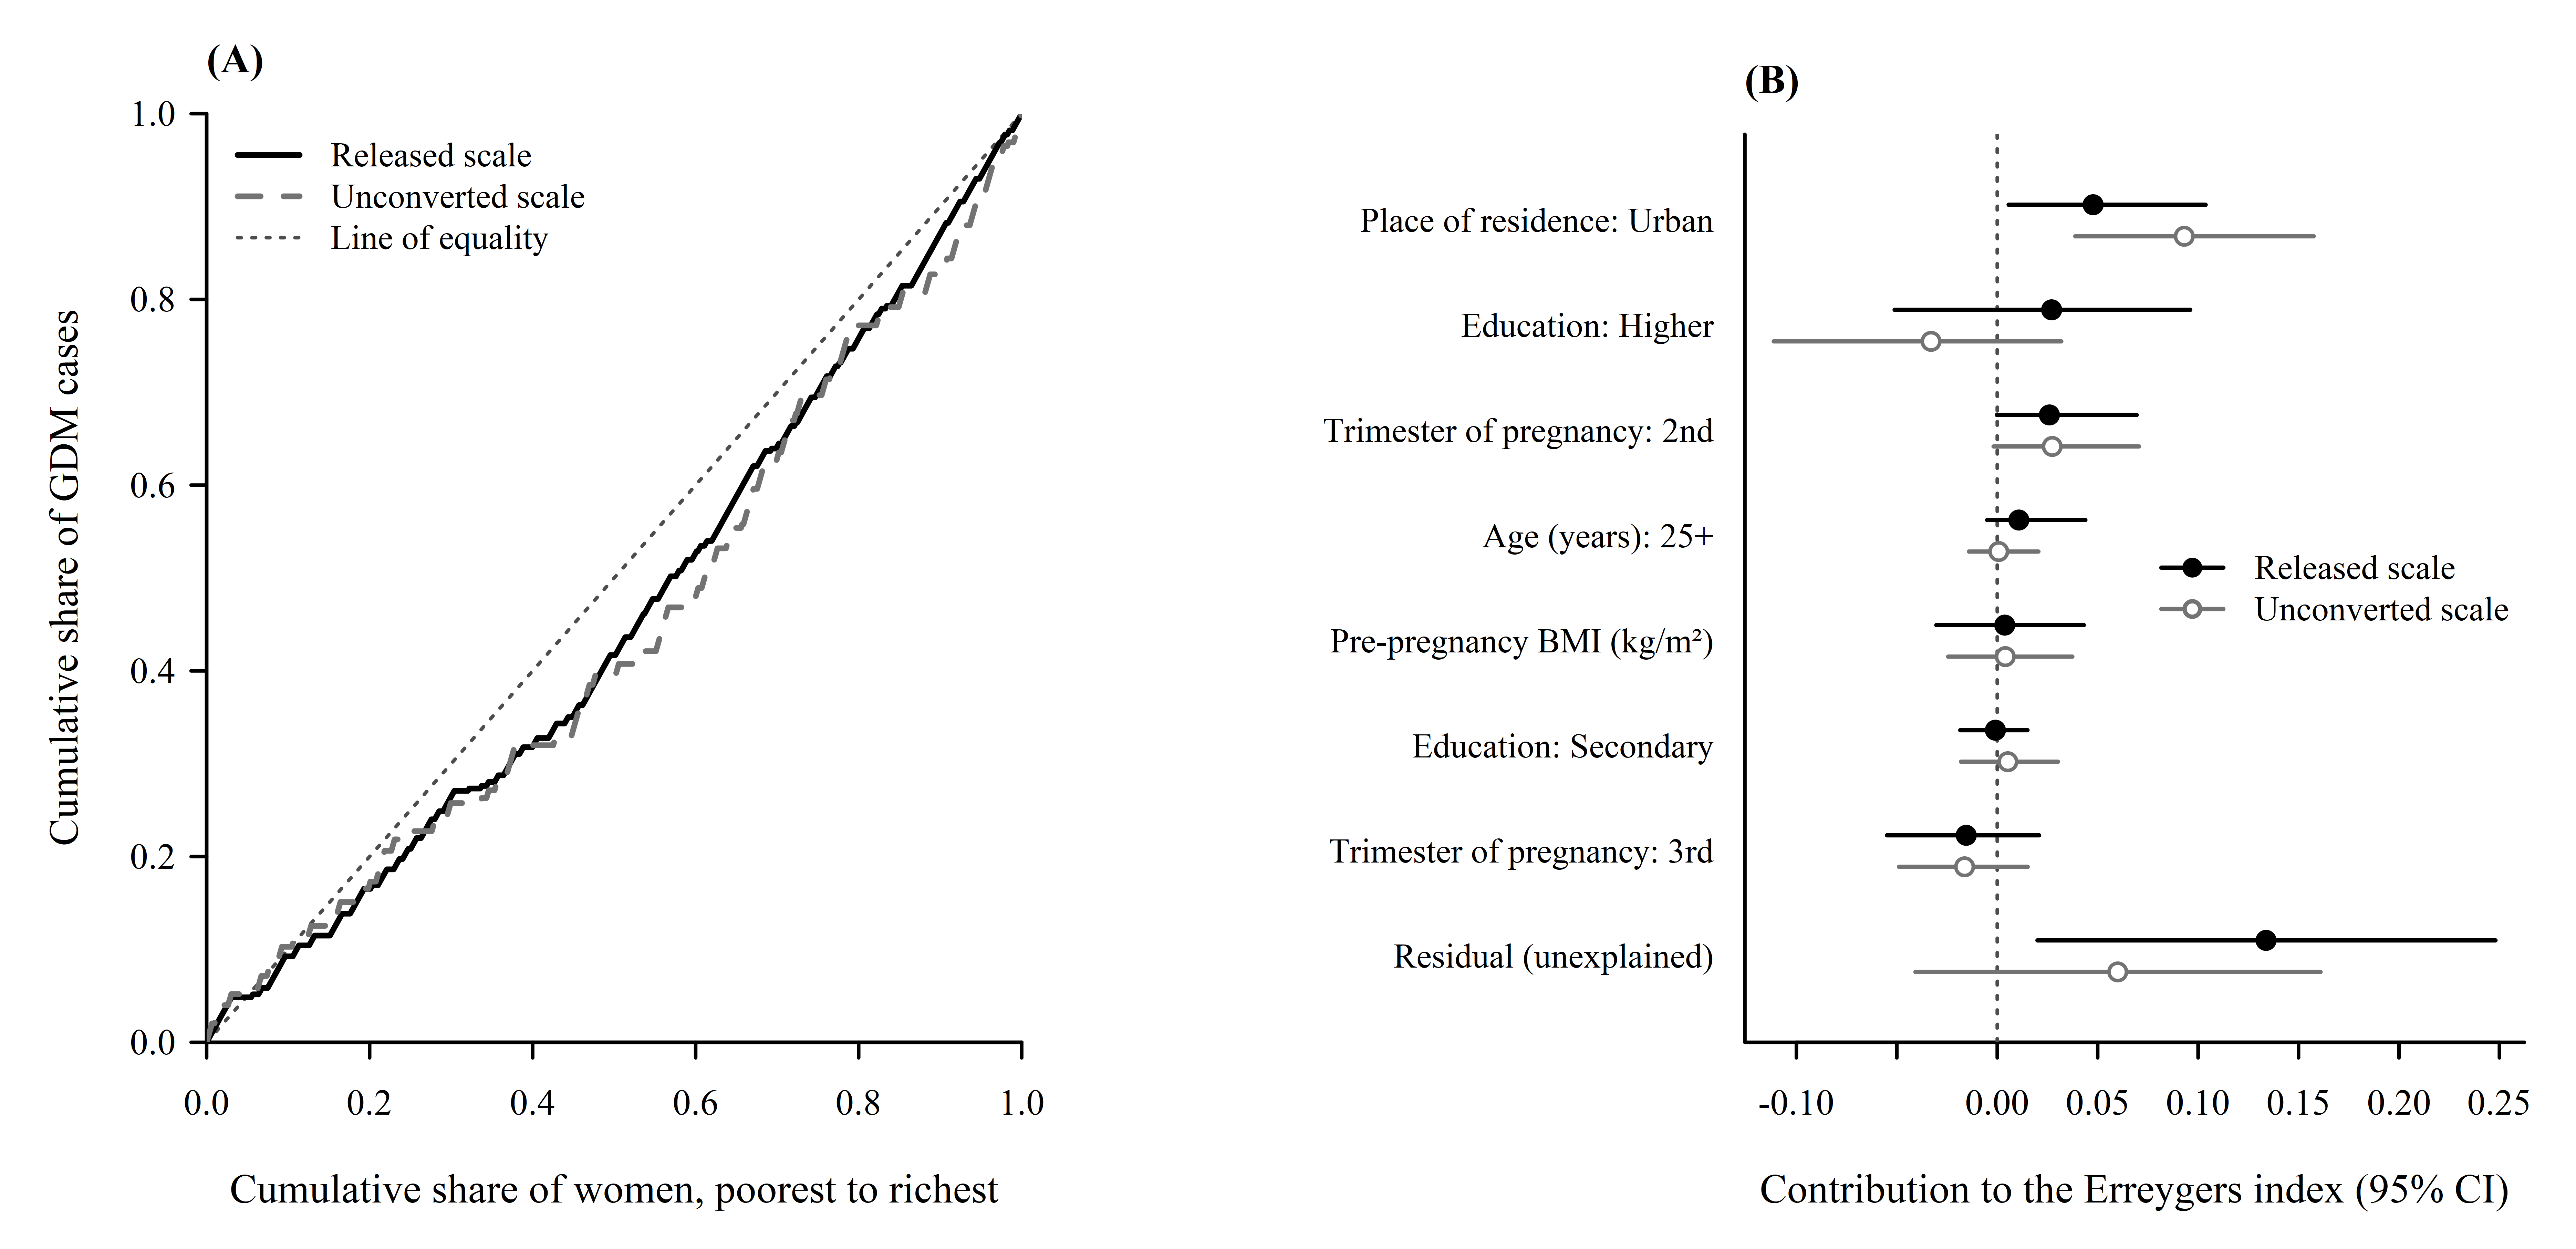

In [8]:
plot_inequality(read_table("concentration_curve"), read_table("decomposition_main"), fig("Figure_2"))

**Fig. SA1.** Calibration of the adjusted logistic model. [Open the file](../output/bdhs2022/figures/Figure_SA1.png)

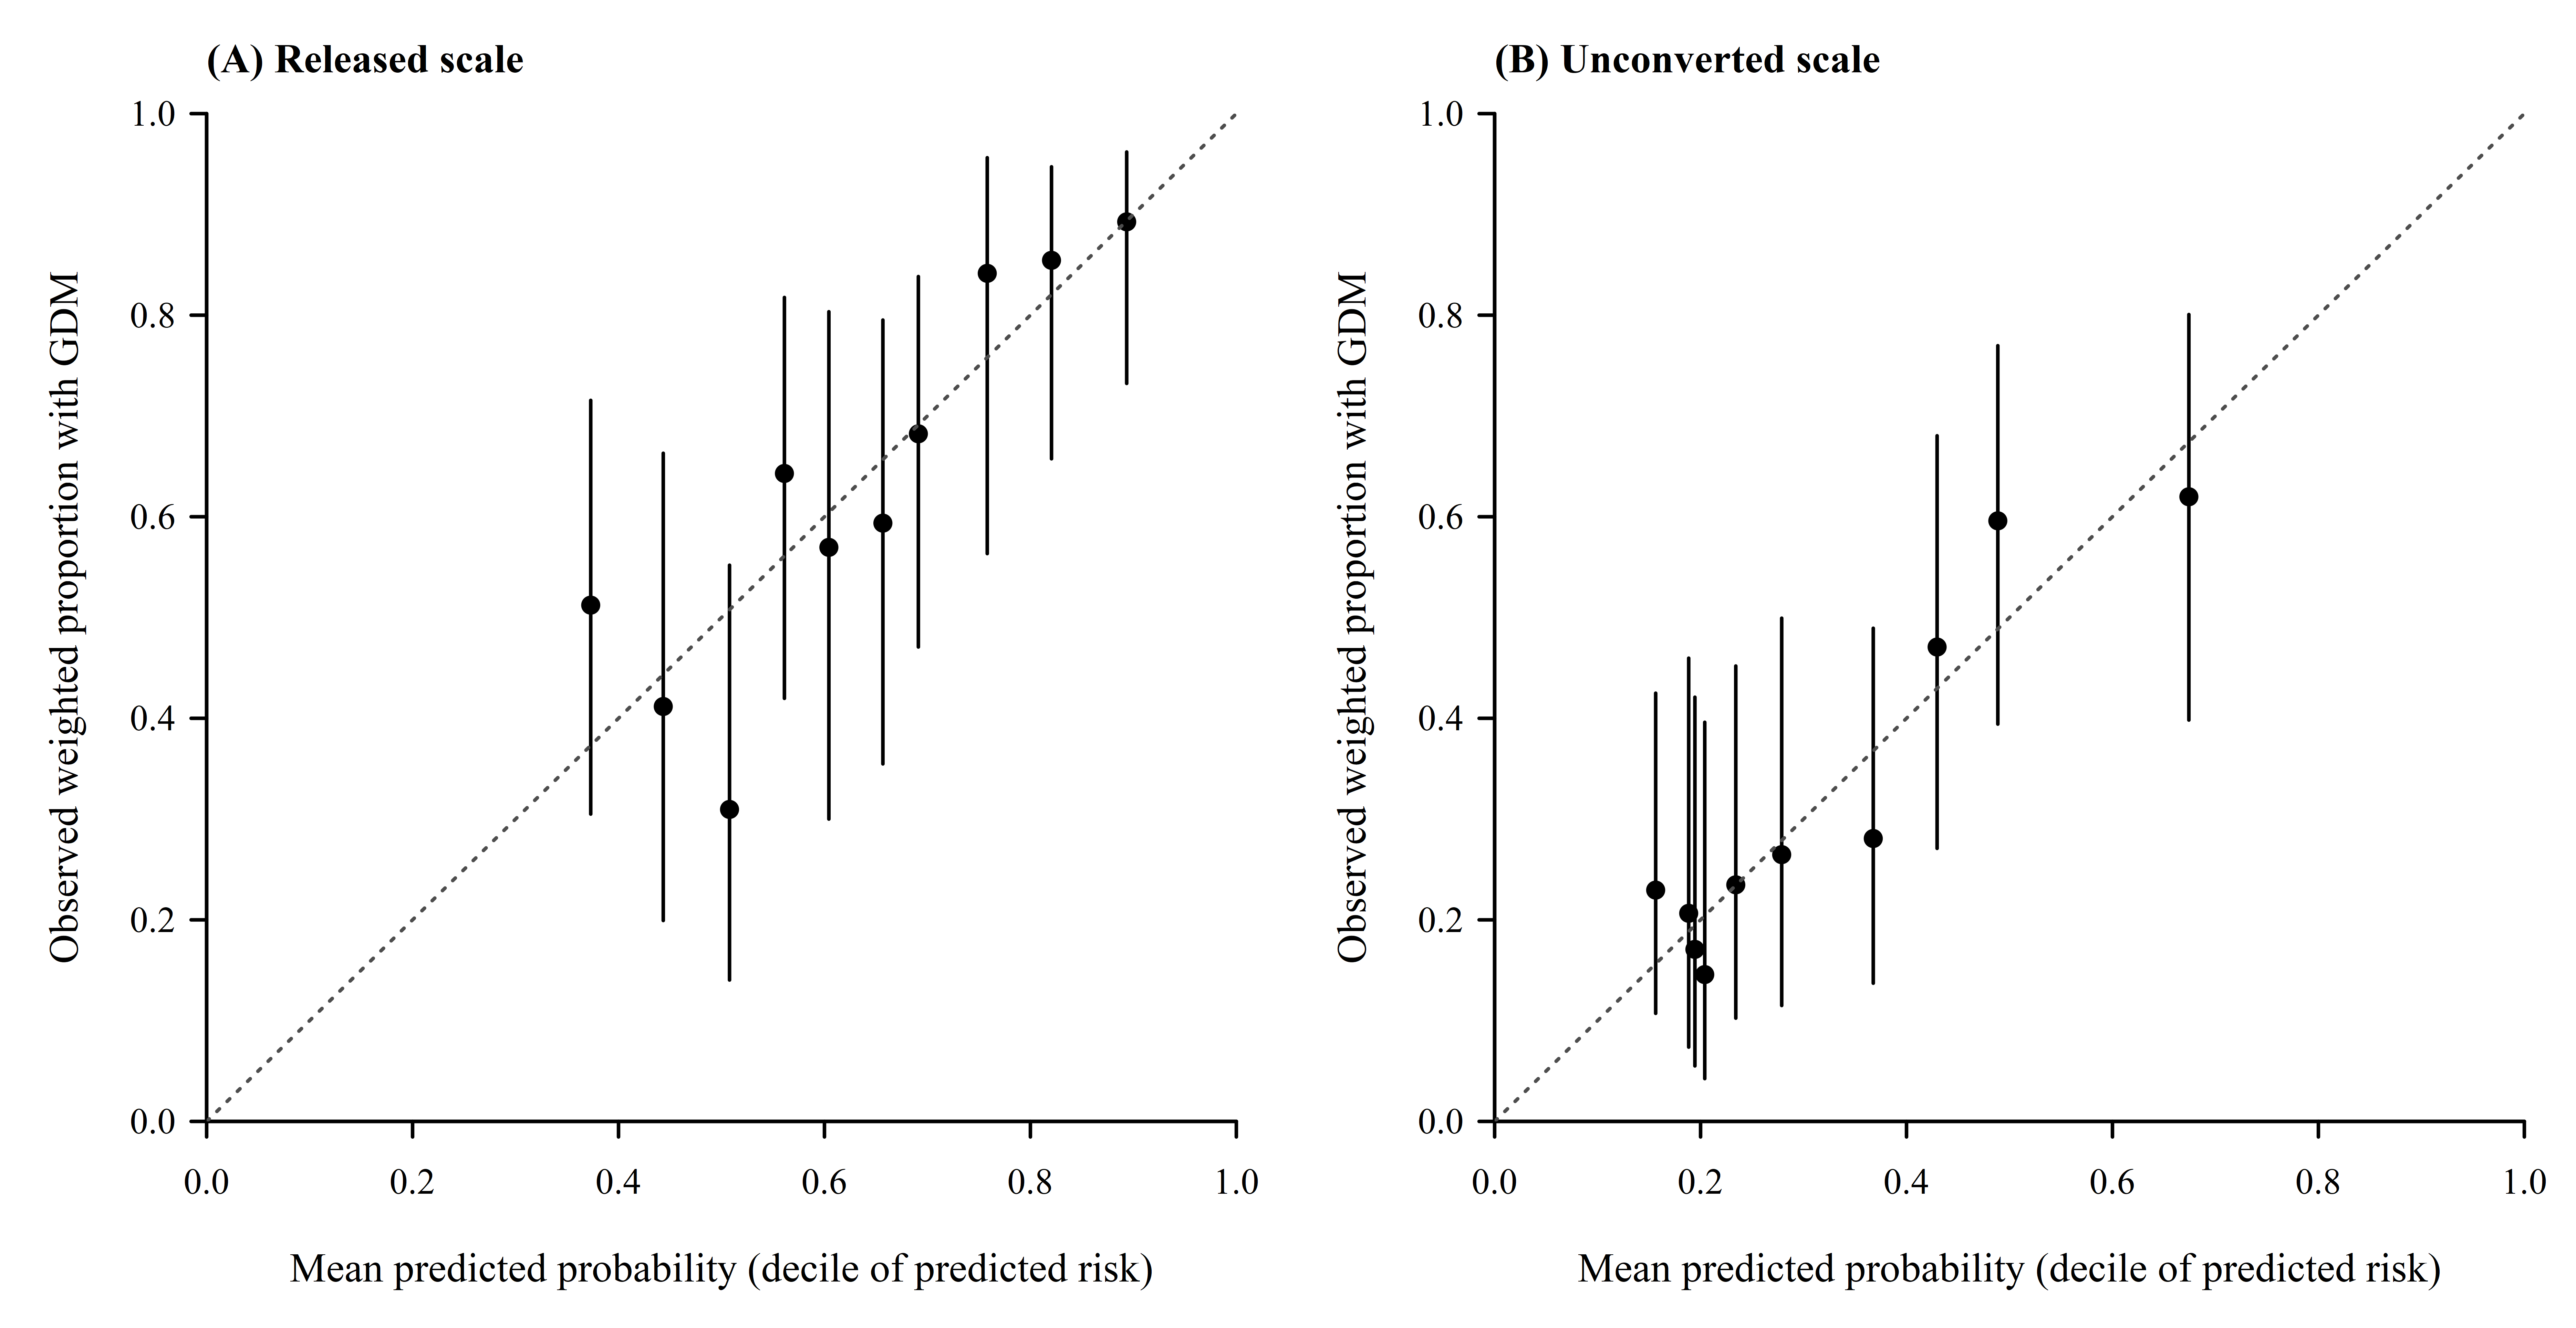

In [9]:
plot_calibration(read_table("calibration_groups"), fig("Figure_SA1"))

**Fig. SA3.** Cumulative distribution of FPG in pregnant and non-pregnant women. [Open the file](../output/bdhs2022/figures/Figure_SA3.png)

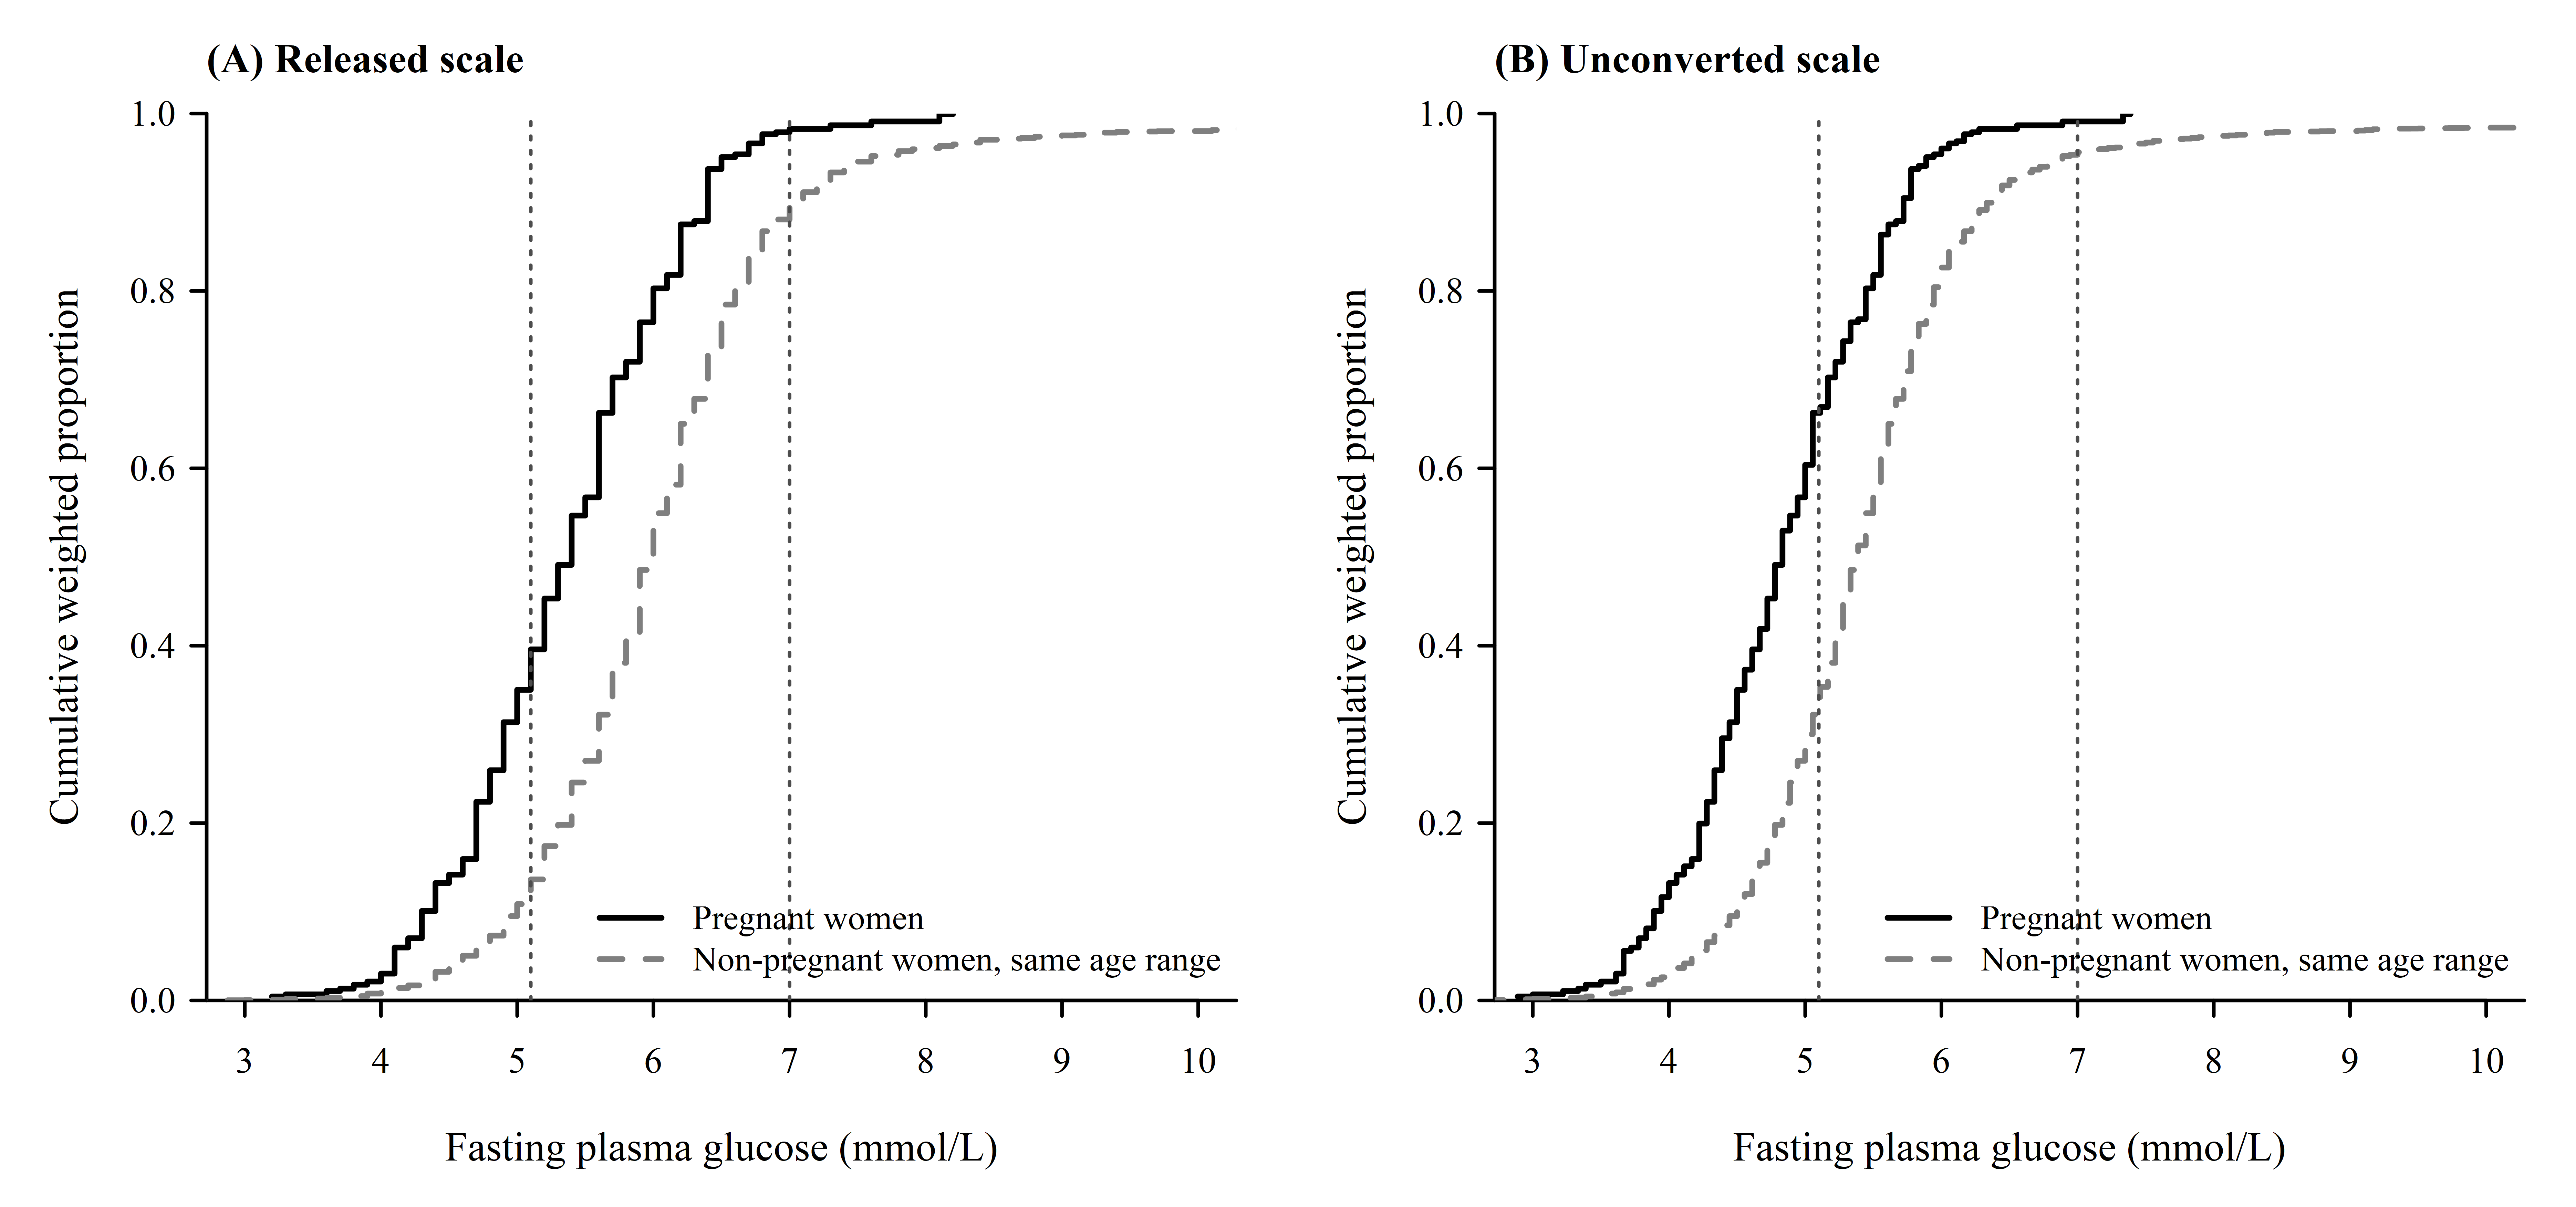

In [10]:
plot_fpg_ecdf(women, fig("Figure_SA3"))

## 3. Checks that do not depend on the glucose scale

These analyses were added after external review. The released value is the unconverted value × 1.11, so log FPG differs between scales by a constant, and the coefficients agree up to rounding. That gives one gradient estimate whatever the calibration.

`base` holds the women without known diabetes who have a value on both scales.

In [11]:
x <- cfg$covariates
base <- sample[sample$pre_dm %in% 0 & !is.na(sample$fpg) & !is.na(sample$fpg_alt), ]

### 3.1 Log-FPG regression

Survey-weighted linear regression of log FPG. Coefficients are shown as percentage differences.

In [12]:
fit_log <- function(d, y, label) {
  d$log_fpg <- log(d[[y]])
  m <- svyglm(reformulate(x, "log_fpg"), design = svy_domain(d, women))
  ci <- confint(m, ddf = degf(m$survey.design))
  data.frame(scale = label, n = nrow(d), term = names(coef(m)), coefficient = coef(m),
             pct_difference = 100 * (exp(coef(m)) - 1),
             ci_lower = 100 * (exp(ci[, 1]) - 1), ci_upper = 100 * (exp(ci[, 2]) - 1),
             p_value = summary(m)$coefficients[, 4], row.names = NULL)
}
log_fpg <- do.call(rbind, lapply(names(scales), function(s) {
  fit_log(base, if (s == "released") "fpg" else "fpg_alt", s)
}))
print(log_fpg)
save_table(log_fpg, "reviewer_log_fpg")

         scale   n           term  coefficient pct_difference    ci_lower    ci_upper      p_value
1     released 270    (Intercept)  1.634091216    412.4798546 361.5829686 468.9889343 4.780435e-78
2     released 270   age_group25+  0.017860196      1.8020643  -2.0124976   5.7651235 3.576527e-01
3     released 270 residenceUrban  0.052633312      5.4043070   1.1218470   9.8681270 1.315833e-02
4     released 270   wealthMiddle  0.034481486      3.5082865  -1.1616009   8.3988153 1.424540e-01
5     released 270  wealthHighest  0.030939508      3.1423109  -1.9647739   8.5154462 2.311261e-01
6     released 270   trimester2nd -0.059894489     -5.8136095  -9.3847545  -2.1017257 2.557335e-03
7     released 270   trimester3rd -0.073561347     -7.0920852 -11.0784914  -2.9269660 1.117591e-03
8     released 270            bmi  0.001892490      0.1894281  -0.2835714   0.6646713 4.313882e-01
9  unconverted 270    (Intercept)  1.531192832    362.3688819 316.3420623 413.4839890 3.067707e-73
10 unconve

### 3.2 Threshold sweep

Adjusted PRs for the highest wealth tertile and urban residence, with GDM defined on the unconverted scale at thresholds from 4.4 to 5.4 mmol/L. `sb267g` is rounded, so released ≥ 5.1 is exactly `sb267` ≥ 82 mg/dL (unconverted 4.56), and this point is added to the grid.

   threshold_unconverted released_equivalent   n events prevalence           term estimate  ci_lower ci_upper
1               4.400000            4.884000 267    184  0.6936571 residenceUrban 1.073162 0.9047609 1.272908
2               4.400000            4.884000 267    184  0.6936571  wealthHighest 1.249865 0.9823969 1.590154
3               4.500000            4.995000 267    179  0.6748859 residenceUrban 1.108645 0.9315102 1.319464
4               4.500000            4.995000 267    179  0.6748859  wealthHighest 1.233089 0.9542018 1.593487
5               4.555556            5.056667 267    170  0.6369863 residenceUrban 1.138358 0.9439884 1.372750
6               4.555556            5.056667 267    170  0.6369863  wealthHighest 1.358357 1.0155591 1.816864
7               4.600000            5.106000 267    163  0.6134866 residenceUrban 1.140030 0.9228452 1.408328
8               4.600000            5.106000 267    163  0.6134866  wealthHighest 1.373920 1.0222334 1.846599
9         

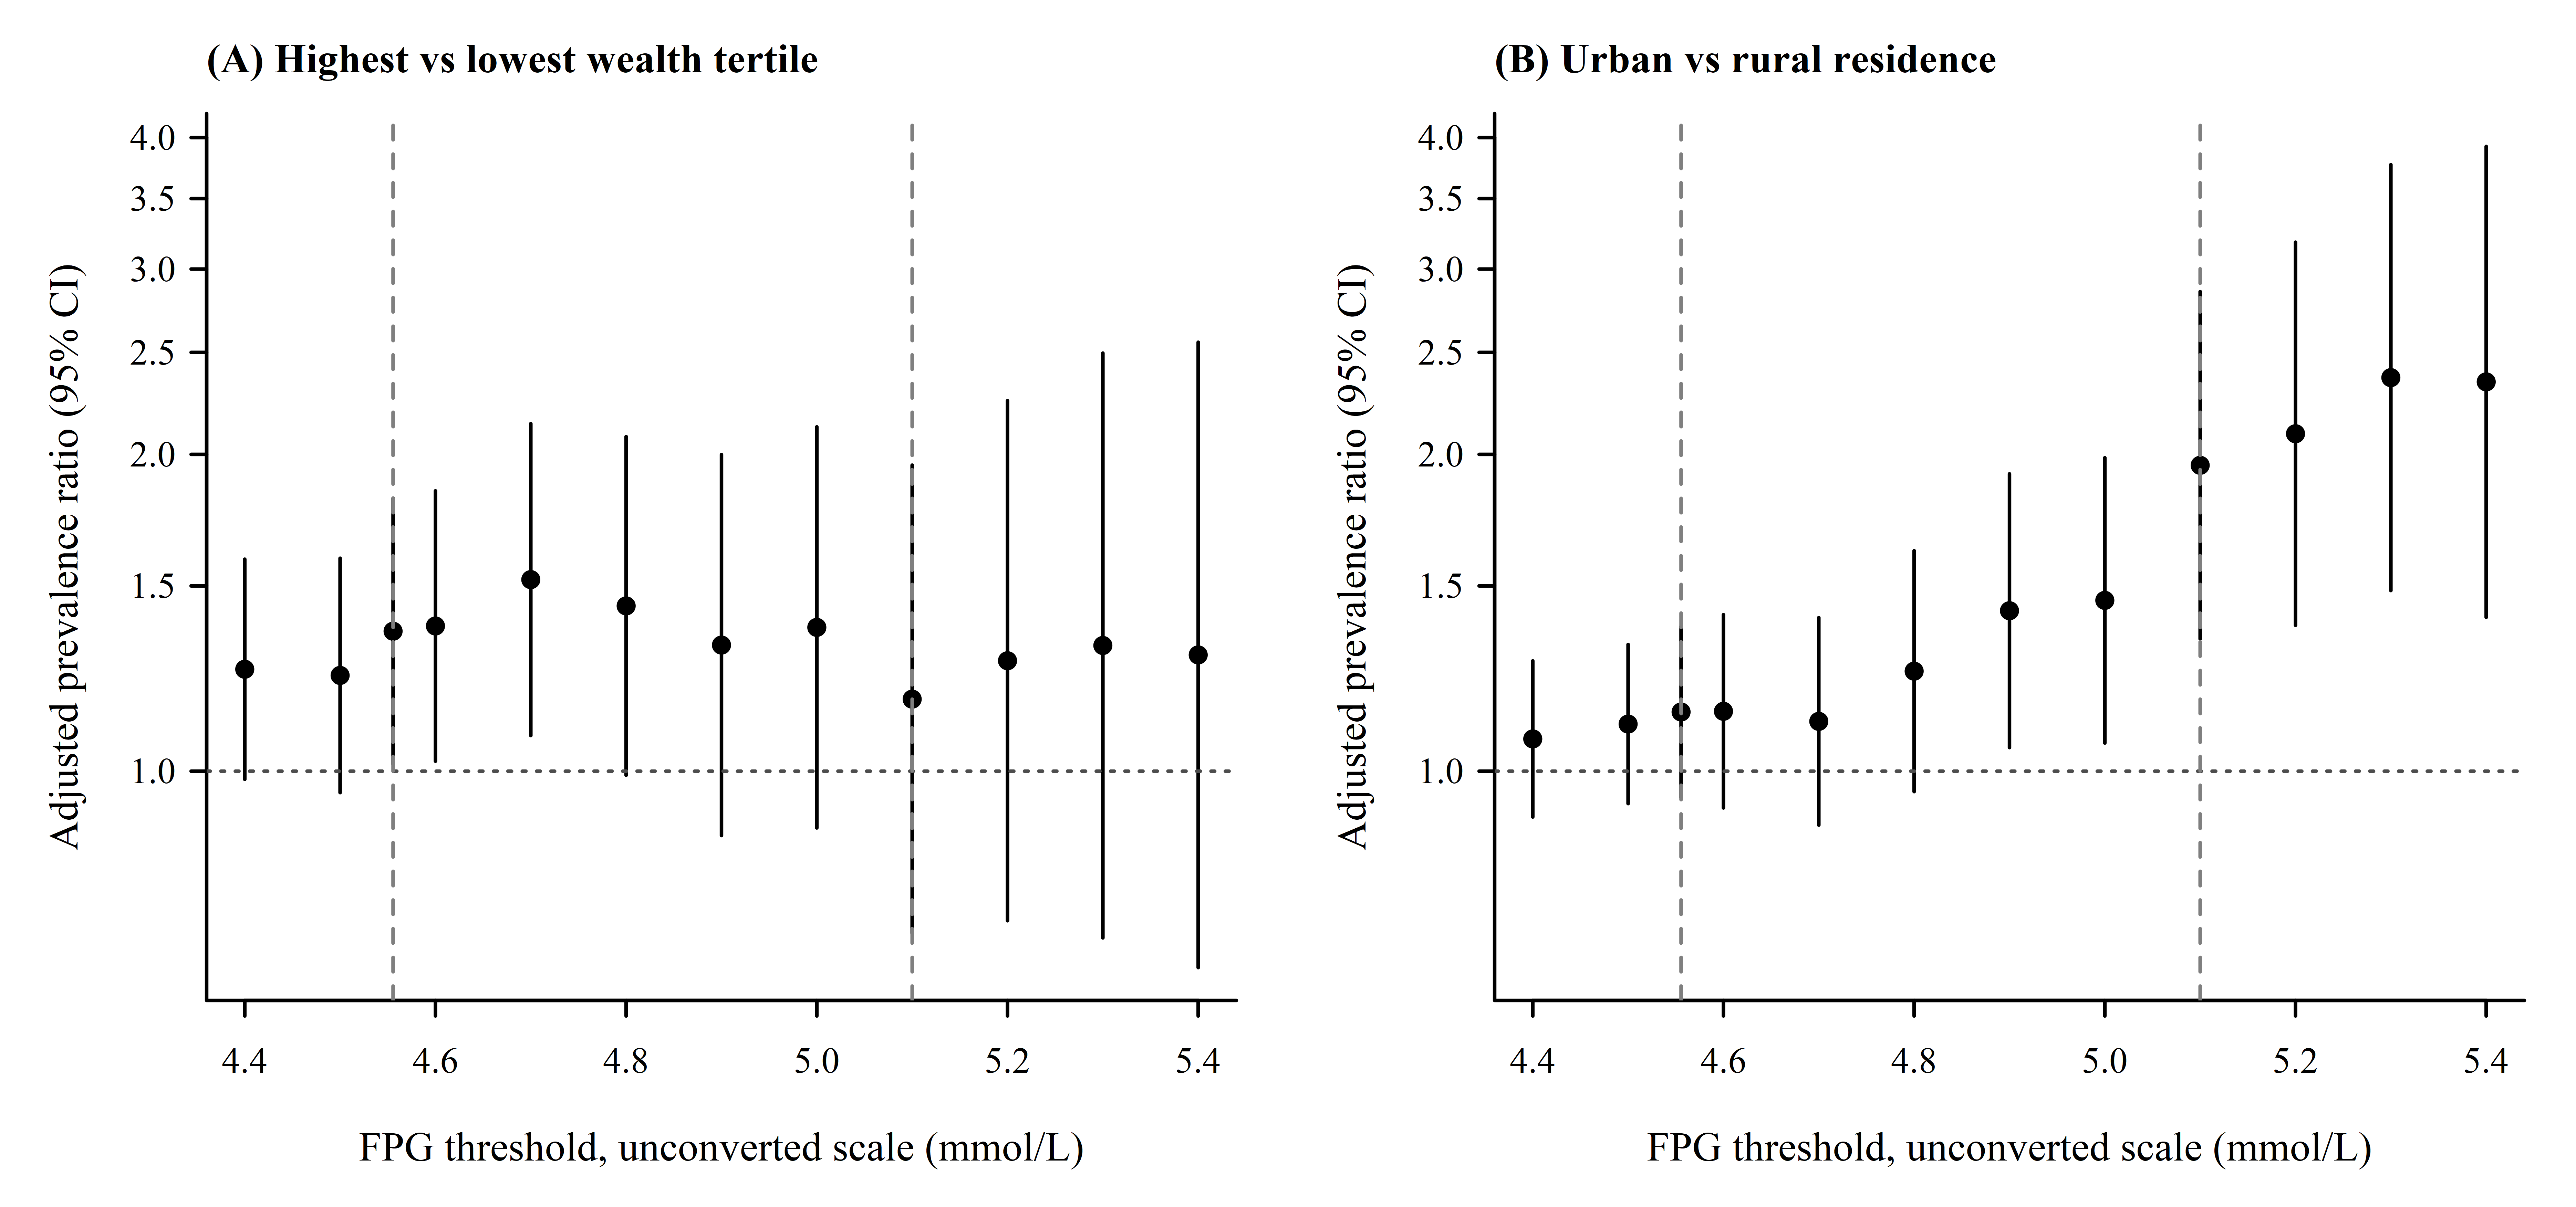

In [13]:
sweep_rows <- base[base$fpg_alt < cfg$fpg_diabetes, ]
thresholds <- sort(c(round(seq(4.4, 5.4, by = 0.1), 1), 82 / 18))
sweep <- do.call(rbind, lapply(thresholds, function(t) {
  d <- sweep_rows
  d$gdm_t <- as.numeric(d$fpg_alt >= t)
  e <- effect_table(fit_pr(svy_domain(d, women), x, "gdm_t"), "PR", "adjusted")
  e <- e[e$term %in% c("wealthHighest", "residenceUrban"), c("term", "estimate", "ci_lower", "ci_upper", "p_value")]
  cbind(threshold_unconverted = t, released_equivalent = t * 1.11, n = nrow(d), events = sum(d$gdm_t),
        prevalence = weighted.mean(d$gdm_t, d$weight), e, row.names = NULL)
}))
print(sweep)
save_table(sweep, "reviewer_threshold_sweep")
plot_threshold_sweep(sweep, file.path(dir_figures, "Figure_SA2.png"))

**Fig. SA2.** Adjusted PRs across unconverted FPG thresholds. [Open the file](../output/bdhs2022/figures/Figure_SA2.png)

### 3.3 Early-pregnancy glucose

FPG by completed month, and fasting duration by trimester. If women tested early had simply fasted for less time, this would explain the higher early prevalence.

In [14]:
by_month <- do.call(rbind, lapply(names(scales), function(s) {
  cbind(scale = s, fpg_by_month(base, women, if (s == "released") "fpg" else "fpg_alt", cfg))
}))
print(by_month)
save_table(by_month, "reviewer_fpg_by_month")

fasting <- fasting_by_trimester(base, women)
print(fasting)
save_table(fasting, "reviewer_fasting_by_trimester")

         scale month  n      q25   median      q75 pct_within_0.3
1     released     1 10 5.700000 5.900000 6.400000        0.00000
2     released     2 31 5.100000 5.800000 6.200000       15.66973
3     released     3 37 5.200000 5.600000 6.000000       32.21335
4     released     4 30 4.700000 5.300000 6.000000       21.60911
5     released     5 37 5.000000 5.400000 5.600000       36.65791
6     released     6 32 4.700000 5.100000 5.900000       35.27677
7     released     7 29 4.900000 5.200000 5.800000       42.56786
8     released     8 41 4.300000 5.100000 5.400000       41.81518
9     released     9 23 4.800000 5.100000 6.100000       37.95829
10 unconverted     1 10 5.111111 5.277778 5.722222       53.64198
11 unconverted     2 31 4.555556 5.222222 5.555556       30.94627
12 unconverted     3 37 4.666667 5.000000 5.444444       32.26903
13 unconverted     4 30 4.222222 4.777778 5.444444       22.52212
14 unconverted     5 37 4.500000 4.833333 5.055556       45.66271
15 unconve

### 3.4 FPG by trimester and slope per completed month

In [15]:
# Weighted quartiles of FPG by trimester
by_trimester <- do.call(rbind, lapply(names(scales), function(s) {
  d <- base
  d$fpg_x <- d[[if (s == "released") "fpg" else "fpg_alt"]]
  des <- svy_domain(d, women)
  do.call(rbind, lapply(levels(d$trimester), function(t) {
    q <- coef(svyquantile(~fpg_x, subset(des, trimester == t), c(0.25, 0.5, 0.75), ci = FALSE))
    data.frame(scale = s, trimester = t, n = sum(d$trimester %in% t), q25 = q[1], median = q[2], q75 = q[3], row.names = NULL)
  }))
}))
print(by_trimester)
save_table(by_trimester, "reviewer_fpg_by_trimester")

        scale trimester  n      q25   median      q75
1    released       1st 78 5.200000 5.600000 6.200000
2    released       2nd 99 4.700000 5.300000 5.800000
3    released       3rd 93 4.700000 5.100000 5.600000
4 unconverted       1st 78 4.722222 5.055556 5.555556
5 unconverted       2nd 99 4.277778 4.777778 5.222222
6 unconverted       3rd 93 4.222222 4.611111 5.055556


In [16]:
# Percentage change in FPG per completed month: unadjusted, and adjusted for
# the covariates of the log-FPG model (trimester replaced by month)
slope <- do.call(rbind, lapply(names(scales), function(s) {
  d <- base
  d$log_fpg <- log(d[[if (s == "released") "fpg" else "fpg_alt"]])
  d$month <- pmin(d$v214, 9)
  des <- svy_domain(d, women)
  do.call(rbind, lapply(c("unadjusted", "adjusted"), function(a) {
    rhs <- if (a == "unadjusted") "month" else c("month", setdiff(x, "trimester"))
    m <- svyglm(reformulate(rhs, "log_fpg"), design = des)
    ci <- confint(m, ddf = degf(m$survey.design))["month", ]
    data.frame(scale = s, model = a, n = nrow(d), pct_per_month = 100 * (exp(coef(m)[["month"]]) - 1),
               ci_lower = 100 * (exp(ci[[1]]) - 1), ci_upper = 100 * (exp(ci[[2]]) - 1),
               p_value = summary(m)$coefficients["month", 4])
  }))
}))
print(slope)
save_table(slope, "reviewer_fpg_slope_by_month")

        scale      model   n pct_per_month  ci_lower   ci_upper     p_value
1    released unadjusted 270     -1.294601 -2.135139 -0.4468440 0.002994956
2    released   adjusted 270     -1.192995 -1.995897 -0.3835157 0.004146191
3 unconverted unadjusted 270     -1.300584 -2.144492 -0.4493991 0.002979062
4 unconverted   adjusted 270     -1.200540 -2.008648 -0.3857673 0.004154469


In [17]:
# Women under 8 hours since eating by the computed times, although flagged as fasted
under8 <- function(d, label) data.frame(group = label, n = nrow(d), n_with_times = sum(!is.na(d$hours_ate)),
                                        n_under_8 = sum(d$hours_ate < 8, na.rm = TRUE))
fasting_times <- rbind(under8(women[biomarker_women(women), ], "All women tested, flagged fasted"),
                       under8(sample, "Analytic sample"), under8(base, "Women without known diabetes"))
print(fasting_times)
save_table(fasting_times, "reviewer_fasting_times")

                             group    n n_with_times n_under_8
1 All women tested, flagged fasted 5012         5012        42
2                  Analytic sample  276          276         1
3     Women without known diabetes  270          270         1


### 3.5 Relative concentration index of continuous FPG

This is the main inequality result that does not depend on where the threshold falls.

In [18]:
boot <- bootstrap_weights(sample, women, cfg)
rows <- sample$pre_dm %in% 0 & !is.na(sample$fpg) & !is.na(sample$fpg_alt)
ci_fpg <- do.call(rbind, lapply(names(scales), function(s) {
  y <- sample[[if (s == "released") "fpg" else "fpg_alt"]][rows]
  r <- sample$wealth_score[rows]
  reps <- apply(boot$weights[rows, ], 2, function(w) { k <- w > 0; concentration_index(y[k], r[k], w[k]) })
  cbind(scale = s, n = length(y), bootstrap_summary(concentration_index(y, r, sample$weight[rows]), reps, boot))
}))
print(ci_fpg)
save_table(ci_fpg, "reviewer_concentration_fpg")

        scale   n   estimate     boot_se    ci_lower   ci_upper    B failed
1    released 270 0.01432621 0.006036175 0.002664829 0.02593007 1000      0
2 unconverted 270 0.01424437 0.006042940 0.002542430 0.02599993 1000      0


### 3.6 Women beyond the x-axis of Fig. SA3

The axis of Fig. SA3 stops at 10 mmol/L. This counts the women above it, for the legend.

In [19]:
groups <- fpg_groups(women)
above_10 <- do.call(rbind, lapply(c(released = "fpg", unconverted = "fpg_alt"), function(v) {
  do.call(rbind, lapply(names(groups), function(g) {
    x <- women[[v]][groups[[g]]]
    data.frame(scale = if (v == "fpg") "released" else "unconverted", group = g,
               n = sum(!is.na(x)), n_above_10 = sum(x > 10, na.rm = TRUE))
  }))
}))
print(above_10)
save_table(above_10, "reviewer_fpg_above_10")

                    scale        group    n n_above_10
released.1       released     pregnant  276          0
released.2       released non_pregnant 3662         74
unconverted.1 unconverted     pregnant  276          0
unconverted.2 unconverted non_pregnant 3662         58


**Next:** `05_bdhs2017`.